In [21]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '7c10a352'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'e7a6a15d'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '900b301f'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/kailani-boop/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [22]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [24]:
spills = pd.read_csv('data/Spill_Incidents_20261102.csv')

fp = os.path.join('data','tl_2026_us_county','tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_I looked at the first five rows of the dataframe to see what the columns are, what the format is, and what he different observations might be. I also looked at the type of each column to gain more insight on the columns. Then, I checked out the value counts in the material family column where there were four different types. I also checked the unique values in the county column. It returned an array of about 60 counties. I also looked at the number of `NA` values in each column of the dataset. I saw that there were a lot for the zipcode column, so then I checked the value counts for zipcode. It didn't provide very much information._

In [25]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [26]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [27]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].value_counts()

Material Family
Petroleum             485789
Other                  70882
Hazardous Material     17662
Oxygenates               399
Name: count, dtype: int64

In [28]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

In [29]:
spills.isna().sum()

Spill Number                  0
Program Facility Name         6
Street 1                    134
Street 2                 529997
Locality                   1151
County                        0
ZIP Code                 516823
SWIS Code                     0
DEC Region                    0
Spill Date                  151
Received Date               503
Contributing Factor           0
Waterbody                526740
Source                        0
Close Date                12421
Material Name                 0
Material Family               0
Quantity                      0
Units                    121368
Recovered                     0
dtype: int64

In [31]:
spills['ZIP Code'].value_counts()

ZIP Code
14624     915
14450     734
14150     690
14580     681
14606     591
         ... 
10971       1
1344        1
14741       1
10545       1
145813      1
Name: count, Length: 2278, dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [32]:
# Simplifying columns so that they're easier to work with
# Convert to lower case
# Replace spaces with `_`
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [33]:
# Updating the necessary columns to the correct data types
# Convert zip code, quantity, recovered to int potentially
# Convert date columns to a datetime
dates = ['spill_date', 'received_date', 'close_date']
spills[dates] = spills[dates].apply(pd.to_datetime)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [34]:
# Creating a new variable of spills in 2023
petr_23 = spills[(spills['spill_date'] >= '01/01/2023') & (spills['spill_date'] <= '12/31/2023') & (spills['material_family'] == 'Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [35]:
# Verifying that petr_23 only has data from 2023
print(f"The 'petr_23' dataset only has data from {petr_23['spill_date'].dt.year.unique().tolist()}.")

The 'petr_23' dataset only has data from [2023].


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [36]:
# Writing an assertion test checking if spills only include petroleum
assert petr_23['material_family'].nunique() == 1, "More than one type of spills."

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_No, the numbers are not the same. There are 8,468 total rows and 8,228 unique spills. Some of the unique spill ID's appear two to nine times, while the rest only appear once. For the ID with nine counts, the rows say that it was a 'test spill'. For the rest of the ID counts greater than 1, there appears to be multiple material names spilled that are still considered to be in the 'petroleum' material family._

In [37]:
# Print statement to compare number of rows and unique spill numbers
print(f"There are {len(petr_23)} rows and {petr_23['spill_number'].nunique()} unique spills.")

There are 8468 rows and 8228 unique spills.


In [38]:
# Looking at the value counts to see which ID's were repeated
petr_23['spill_number'].value_counts(dropna = False)

spill_number
2301892    9
2208799    4
2302323    3
2302927    3
2300963    3
          ..
2208417    1
2303194    1
2300384    1
2307142    1
2304668    1
Name: count, Length: 8228, dtype: int64

In [39]:
# Using the value counts from above, I check the rows to see what's happening
petr_23[petr_23['spill_number'] == 2208799]

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
96139,2208799,CITGO GAS STATION,451 WEST CLARKSTOWN RD,NaN,NEW CITY,Rockland,NaN,4422,3,2023-01-31,2023-01-31,Other,NaN,Gasoline Station or other PBS Facility,NaT,#2 fuel oil,Petroleum,0,NaN,0
96140,2208799,CITGO GAS STATION,451 WEST CLARKSTOWN RD,NaN,NEW CITY,Rockland,NaN,4422,3,2023-01-31,2023-01-31,Other,NaN,Gasoline Station or other PBS Facility,NaT,diesel,Petroleum,0,NaN,0
96141,2208799,CITGO GAS STATION,451 WEST CLARKSTOWN RD,NaN,NEW CITY,Rockland,NaN,4422,3,2023-01-31,2023-01-31,Other,NaN,Gasoline Station or other PBS Facility,NaT,gasoline,Petroleum,0,NaN,0
96175,2208799,CITGO GAS STATION,451 WEST CLARKSTOWN RD,NaN,NEW CITY,Rockland,NaN,4422,3,2023-01-31,2023-01-31,Other,NaN,Gasoline Station or other PBS Facility,NaT,waste oil/used oil,Petroleum,0,NaN,0


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [40]:
# Checking to see the number of unique counties
petr_23['county'].nunique()

66

In [41]:
# Checking the number of unique spill ID's
petr_23['spill_number'].nunique()

8228

In [42]:
# Creating a new dataset with the number of spills per county from `petr_23` dataset
# Grouping by county 
# Counts each unique spill 
# Resets the index so that it starts from 0. Names the new columns 'n_spills'
spills_per_county = (petr_23.groupby('county')['spill_number'].nunique().reset_index(name = 'n_spills'))

# Rechecking that the dataset has 66 rows and 2 columns
spills_per_county.shape # (66, 2)

# Rechecking that the total number of spills is 8228
spills_per_county['n_spills'].sum()

8228

In [43]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_I checked the first 5 rows of the dataframe and the data types of each column. The majority of them are objects, there's a few integers, and one geometry column. I also looked at the CRS of it, which was EPSG:4269. Lastly, I plotted the `counties` dataframe. It appears that Alaska wraps around the latitude/longitude so the map is very wide. Or, the wideness could come from different US territories._

In [ ]:
# a. Looking at the head of the counties dataframe
counties.head()


,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [45]:
# b. Checking the data type of each column
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [46]:
# c. Checking the CRS of the dataframe
counties.crs # EPSG:4269

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

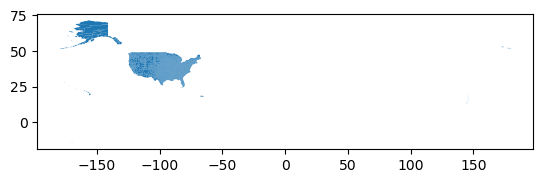

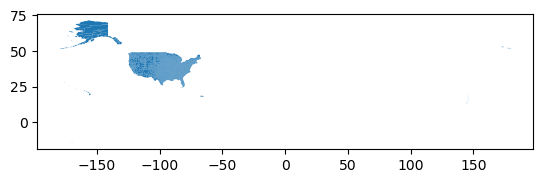

In [48]:
# d. Plotting the counties dataframe
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [ ]:
# Converting the columns from upper case to lower case
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

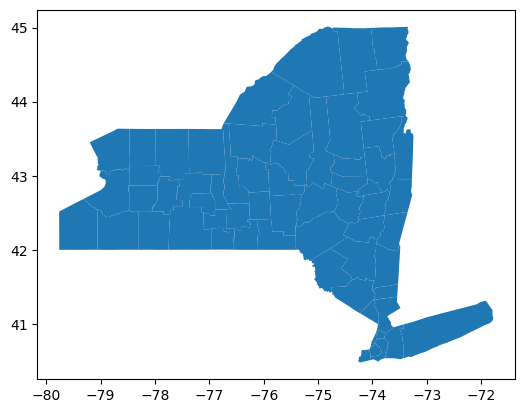

In [ ]:
# Filtering the data frame to only include counties within NY
# NY code is 36
ny_counties = counties[counties['statefp'] == '36']

# Plotting the new data frame
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
# a. Printing the names of each unique county in New York
print(ny_counties['name'].unique())

# Checking the number of unique counties
len(ny_counties['name'].unique())  # 62

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


62

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [ ]:
# b. Printing the names of counties in spills_per_county
print(spills_per_county['county'].unique())

# Checking the number of unique counties
len(spills_per_county['county'].unique())  # 66

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


66

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
# c. Checking what the missing counties are in ny_counties
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])
diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [63]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
# d. Checking what the missing counties are in spills_per_county
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [65]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. Looking at the number of spills in Tuscarora Indian Reservation
spills_per_county[spills_per_county['county'] == 'Tuscarora Indian Reservation']  # 2

,county,n_spills
58,Tuscarora Indian Reservation,2


In [ ]:
# Looking at the number of spills in Onondaga Indian Reservation
spills_per_county[spills_per_county['county'] == 'Onondaga Indian Reservation']  # 1

,county,n_spills
35,Onondaga Indian Reservation,1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [ ]:
# Fixing the St. Lawrence issue
spills_per_county['county'] = spills_per_county['county'].replace('St Lawrence', 'St. Lawrence')
# Verifying that the issue was fixed
assert spills_per_county['county'].str.contains('St. Lawrence').any()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [84]:
# a. Renaming the name column to county
ny_counties = ny_counties.rename(columns = {'name': 'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [85]:
# b. Merging the data frames together into a new variable
ny_spills = pd.merge(spills_per_county, ny_counties, how = 'inner', on = 'county')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [ ]:
# c. Checking if anything was dropped from ny_counties
np.setdiff1d(ny_counties['county'], ny_spills['county'])

array([], dtype=object)

In [ ]:
# Checking what was dropped from spills_per_county
np.setdiff1d(spills_per_county['county'], ny_spills['county'])  # The same 4 from earlier

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'],
      dtype=object)

In [ ]:
# Verifying the shape is off by 4
ny_spills.shape

(62, 20)

In [ ]:
# Looking at what exactly was dropped and their respective spill counts
dropped = spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]
dropped

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Dropping these records won't create that big of a difference. In total there were 11 spills. Two of the counties are from outside of New York, which were New Jersey and Pennsylvania. The outside state spills add up to be 8 dropped spills. The other two dropped counties are reservations, which are in New York, but aren't actual counties. This makes up 3 of the 11 dropped spills. Removing them shouldn't make much of a difference in the map, but it's worth noting._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [91]:
# e. Save the before values so we can verify the update
before = ny_spills.loc[ny_spills['county'].isin(['Niagara', 'Onondaga']), ['county', 'n_spills']]
before

,county,n_spills
31,Niagara,97
33,Onondaga,214


In [92]:
# Get the reservation spill counts
tuscarora = dropped.loc[dropped['county'] == 'Tuscarora Indian Reservation', 'n_spills'].item()
onondaga_res = dropped.loc[dropped['county'] == 'Onondaga Indian Reservation', 'n_spills'].item()

# Add them to their surrounding counties
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += tuscarora
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += onondaga_res

In [93]:
# Verify the update
after = ny_spills.loc[ny_spills['county'].isin(['Niagara', 'Onondaga']), ['county', 'n_spills']]
after

,county,n_spills
31,Niagara,99
33,Onondaga,215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



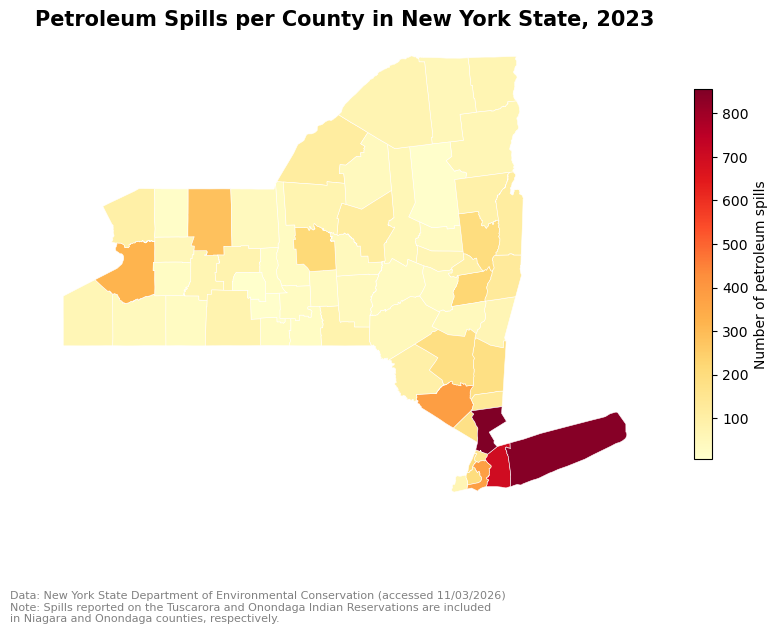

In [98]:
# pd.merge with a regular DataFrame on the left returns a plain DataFrame,
# so convert it back to a GeoDataFrame before plotting
ny_spills = gpd.GeoDataFrame(ny_spills, geometry='geometry', crs=ny_counties.crs)

fig, ax = plt.subplots(figsize=(10, 8))

ny_spills.plot(ax = ax,
               column = 'n_spills',
               cmap = 'YlOrRd',
               edgecolor = 'white',
               linewidth = 0.4,
               legend = True,
               legend_kwds = {'label': 'Number of petroleum spills',
                             'shrink': 0.6})

ax.set_title('Petroleum Spills per County in New York State, 2023',
             fontsize = 15, fontweight = 'bold')
ax.axis('off')

fig.text(0.1, 0.06,
         'Data: New York State Department of Environmental Conservation (accessed 11/03/2026)\n'
         'Note: Spills reported on the Tuscarora and Onondaga Indian Reservations are included\n'
         'in Niagara and Onondaga counties, respectively.',
         fontsize = 8, color = 'gray', ha = 'left')

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

In [ ]:
ny_spills.sort_values('n_spills', ascending=False)[['county', 'n_spills']].head(5)

,county,n_spills
59,Westchester,855
51,Suffolk,845
29,Nassau,698
35,Orange,382
40,Queens,380


In [101]:
ny_spills['n_spills'].describe()

count     62.000000
mean     132.580645
std      174.730758
min        7.000000
25%       41.250000
50%       67.500000
75%      147.500000
max      855.000000
Name: n_spills, dtype: float64

#### Reflection

**How the map was created:** I filtered the NYSDEC spills data to petroleum spills reported between January and December 2023. Because a single spill can appear in multiple rows (one per material spilled), I grouped by county and counted unique spill numbers. Then, I joined these counts to a New York county shapefile with an inner join. Before joining, there was a naming mismatch that I fixed ("St Lawrence" vs. "St. Lawrence"). Also, the key column got renamed so both dataframes matched. The join dropped 11 spills: 8 from regions in New Jersey and Pennsylvania, which fall outside the map, and 3 from the Tuscarora and Onondaga Indian Reservations, which were reassigned to Niagara and Onondaga counties. Finally, I created the choropleth with geopandas using a yellow-orange-red color scale.

**Key takeaways:** Westchester had the most petroleum spills in 2023 at 855 spills, followed by Suffolk (845) and Nassau (698). These three account for 29% of the total spills. They're followed by Orange and Queens county with 382 and 380 spills respectively. Spills tend to be concentrated in the New York City metro area, while rural northern counties reported far fewer. The median county had 67.5 spills, while the mean was 132.5. These numbers are relatively small compared to the maximum of 855. Additionally, the minimum number of spills was only seven. Raw counts partly reflect population and infrastructure, so normalizing by population or area would give a fairer comparison between counties.

**Reflection on the reservation spills and the CARE Principles:** Reassigning the Tuscarora and Onondaga Reservation spills to Niagara and Onondaga counties let us show those spills on a county map. However, it also erased the fact that they happened on the lands of sovereign Indigenous nations. The original NYSDEC data recorded them separately, and my choice merged them into county jurisdictions those nations are not part of.

- **Collective Benefit:** Folding these spills into county totals makes environmental burdens on tribal lands invisible. That makes the data less useful to the Tuscarora and Onondaga Nations for monitoring and advocacy.
- **Authority to Control:** I made this decision without input from either Nation, even though the data describes events on their lands.
- **Responsibility:** I tried to be transparent by documenting the change in a note on the map. A more responsible approach would keep the reservations as their own units, for example by mapping reservation boundaries from the Census AIANNH dataset alongside the counties.
- **Ethics:** Treating reservations as parts of counties repeats a long pattern of data systems that overlook tribal sovereignty. Because the numbers are small (3 spills total), the reassignment barely changes the map. But the effect on representation matters more than the effect on the numbers.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.